# 03. Models

This notebook estimates four models of how LG compares with Samsung, using the two files built by `01_build_tv_dataset.py`. The descriptive analysis in `02_preliminary_analysis.ipynb` splits LG's shortfall in purchased considerations into reach, considerations per reaching session and conversion (Figure 2.4). The models examine adjusted conversion, the choice among the models opened within a visit, and the considerations drawn by each product.

1. **Conversion.** Does LG convert less than Samsung conditional on the observed browsing state, the price and the week (Model 1)? Among the models a shopper opened in one visit before buying, is the LG model less often the one bought (Model 2)?
2. **Considerations per product.** Does an observed LG model draw fewer considerations than an observed Samsung model at the same price (Model 3)? This comparison across products is related to the reach factor but measures something different, as Section 5 explains, and it does not re-estimate brand-level reach.

Model 4 is an optional extension. It describes how traffic and conversion move when the same model's recorded price changes, under assumptions about prices on days without events that Section 6 sets out.

All four models describe associations. None of them identifies what would happen if LG changed its price, placement, assortment or pages.

**Timing of the controls.** In Models 1, 2 and 4a, the browsing controls and the price describe the situation recorded when the shopper first opens the model. `top_model` is the one retrospective control, used for the interaction in Model 1c, for the split into top and other models and as a covariate in Model 2. Model 3 uses each product's median first-view price over the whole period, and Models 4b and 4c use prices aggregated within the day or the week, including carried-over prices. These are retrospective summaries, which could not be used to predict a purchase at the moment of the first view.

Section 7 records which specification choices were made before and after seeing the results.

## Inference convention

The procedures below were fixed before the conclusions were written. Each conclusion in this notebook names the procedure it rests on and reports the sensitivity next to it.

| Model | Primary procedure | Sensitivity reported beside it |
| --- | --- | --- |
| Model 1 and Model 4a (considerations) | Standard errors clustered by user and by TV model at the same time (two-way, as in `02_preliminary_analysis.ipynb`), with normal critical values | A wild cluster bootstrap over TV models, one-way by model |
| Model 1 on the 13 top models | The wild cluster bootstrap over models, because two-way clustering with 13 model clusters is unreliable | Two-way clustered errors |
| Model 2 (conditional logit) | A two-way sandwich by user and by model built from scores centred within each visit | One-way errors by user and by model, model-based errors checked against statsmodels, and a bootstrap over users that checks the user component only |
| Model 2 (linear model with visit fixed effects) | Two-way clustered errors | None |
| Model 3 (one row per product) | Heteroskedasticity-robust errors (HC1) | A bootstrap over shoppers that holds the observed products and their median prices fixed |
| Model 4b and 4c (product panels) | Errors clustered by model | None |

The two-way errors let rows of the same user and rows of the same model be related. The wild bootstrap lets rows of the same model be related and treats different models as independent, even when they share a shopper. The two procedures test the same hypothesis that the coefficient is zero under different assumptions about dependence, so both are reported and neither replaces the other.

## 1. Data and variables

Models 1, 3 and 4 use the LG and Samsung considerations, and Model 2 uses all six brands. The columns come from `tv_considerations.csv` and are defined in `tv_considerations_dictionary.md`. The cell below adds a few transformations.

| Variable | Meaning |
| --- | --- |
| `purchased_pp` | 100 if the model was bought in the same visit, 0 otherwise |
| `lg` | 1 for an LG model, 0 for a Samsung model |
| `log_price` | Natural log of the price at the first view |
| `position` | `position_in_session` as an ordered category |
| `tvs_before` | `tvs_opened_before` grouped as 0, 1, 2, 3 to 4, and 5 or more |
| `price_band` | Price at the first view in five bands, under 300, 300 to 450, 450 to 650, 650 to 1,000 and over 1,000 |
| `visit` | The user and session identifiers together |

In [1]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import textwrap
import warnings
import scipy.sparse as sparse
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

DATA_DIR = Path('..') / 'data' / '01_LG_Electronics_Appliances'
OUT = Path('results') / 'models'
for sub in ['tables', 'figures']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
    for old in (OUT / sub).glob('*'):
        old.unlink()
F_CONS, F_EV = 'tv_considerations.csv', 'events_clean.csv'
SEED = 2026
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e4e4', 'axes.axisbelow': True, 'savefig.dpi': 200})

cons = pd.read_csv(DATA_DIR / F_CONS, parse_dates=['first_view'])
events = pd.read_csv(DATA_DIR / F_EV, parse_dates=['event_time'])
events = events[events['product_category'] == 'tv'].reset_index(drop=True)   # TV events of the six TV brands
events['visit'] = events['user_id'] + '|' + events['session_id']

cons['visit'] = cons['user_id'] + '|' + cons['session_id']
cons['purchased_pp'] = 100 * cons['purchased']
cons['log_price'] = np.log(cons['price'])
cons['lg'] = (cons['brand_group'] == 'lg').astype(int)
cons['other_four'] = (cons['brand_group'] == 'other_four').astype(int)
cons['first_tv'] = (cons['position_in_session'] == 'first_tv').astype(int)
cons['position'] = pd.Categorical(cons['position_in_session'], ['first_tv', 'after_same_brand_only', 'after_other_brand'])
cons['tvs_before'] = pd.cut(cons['tvs_opened_before'], [-1, 0, 1, 2, 4, np.inf],
                            labels=['0', '1', '2', '3 to 4', '5 or more'])
cons['price_band'] = pd.cut(cons['price'], [0, 300, 450, 650, 1000, np.inf],
                            labels=['Under 300', '300 to 450', '450 to 650', '650 to 1,000', 'Over 1,000'])

ls = cons[cons['brand_group'].isin(['lg', 'samsung'])].reset_index(drop=True)
ls[['rival_opened_before', 'own_other_model_opened_before']] = ls[['rival_opened_before', 'own_other_model_opened_before']].astype(int)

print(f"{len(cons):,} considerations in all, {len(ls):,} of them LG or Samsung "
      f"({ls['lg'].sum():,} LG and {(1 - ls['lg']).sum():,} Samsung)")
print(f"{ls['product_id'].nunique()} LG and Samsung models observed with at least one view, {ls['user_id'].nunique():,} users, "
      f"weeks {ls['week'].min()} to {ls['week'].max()}")

115,711 considerations in all, 74,712 of them LG or Samsung (22,213 LG and 52,499 Samsung)
196 LG and Samsung models observed with at least one view, 35,871 users, weeks 40 to 48


## 2. Helper functions

**`ols2`** estimates a linear model by ordinary least squares with standard errors clustered by user and by model.

**`wild_p`** gives the p-value of a wild cluster bootstrap over TV models for one coefficient. The steps are these.
1. Estimate the model without the variable being tested, which imposes the hypothesis that its coefficient is zero.
2. Build a new outcome by adding the residuals back with a random sign, the same sign for every row of the same TV model.
3. Re-estimate the full model on the new outcome and record the t-statistic of the tested coefficient, using errors clustered by model.
4. Repeat 9,999 times. The p-value is the share of repetitions whose t-statistic is at least as large, in absolute value, as the one in the real data.

With 16 or fewer models the function tries every pattern of signs (8,192 patterns for 13 models). This removes simulation noise from the p-value. The test is still an approximation whose accuracy depends on the number of models and on how evenly their rows are spread. The function works with sums by model, so it never reruns a regression, and it was checked against a version that reruns every regression.

**`save_table`** and **`save_figure`** save an exhibit to `results/models/` and record its title, note and the files it is built from.

In [2]:
EXHIBITS = []


def save_table(tid, title, df, src, note=''):
    path = OUT / 'tables' / f"T{tid.replace('.', '_')}.csv"
    df.to_csv(path)
    EXHIBITS.append({'Exhibit': f'Table {tid}', 'Title': title, 'Note': note, 'File': f'tables/{path.name}',
                     'Built from': ', '.join(src)})
    display(Markdown(f'**Table {tid}. {title}**'))
    display(df)
    display(Markdown(f'*Note.* {note} Built from {", ".join(src)}.'.replace('*Note.*  ', '*Note.* ')))
    return df


def save_figure(fig, fid, title, note, src):
    full = f'{note} Built from {", ".join(src)}.'
    w, _ = fig.get_size_inches()
    fig.suptitle(f'Figure {fid}. {title}', x=0.01, ha='left', fontsize=10.5, fontweight='bold')
    fig.text(0.01, -0.015, '\n'.join(textwrap.wrap('Note. ' + full, width=int(w * 17))), fontsize=7.2,
             color='#555555', ha='left', va='top')
    path = OUT / 'figures' / f"F{fid.replace('.', '_')}.png"
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    EXHIBITS.append({'Exhibit': f'Figure {fid}', 'Title': title, 'Note': full, 'File': f'figures/{path.name}',
                     'Built from': ', '.join(src)})
    display(Image(filename=str(path), width=820))


def ols2(formula, d):
    groups = np.column_stack([pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]])
    return smf.ols(formula, d).fit(cov_type='cluster', cov_kwds={'groups': groups})


def wild_p(formula, d, term='lg', draws=9999, seed=SEED):
    m = smf.ols(formula, d)
    j = m.exog_names.index(term)
    z, X, y = m.exog[:, j], np.delete(m.exog, j, axis=1), m.endog
    XtX_inv = np.linalg.pinv(X.T @ X)
    u = y - X @ (XtX_inv @ (X.T @ y))
    zt = z - X @ (XtX_inv @ (X.T @ z))
    S = zt @ zt
    codes, uniq = pd.factorize(d['product_id'])
    G = len(uniq)
    c = np.bincount(codes, weights=zt * u, minlength=G)
    q = np.bincount(codes, weights=zt * zt, minlength=G)
    Dm = np.zeros((G, X.shape[1])); np.add.at(Dm, codes, X * zt[:, None])
    Am = np.zeros((G, X.shape[1])); np.add.at(Am, codes, X * u[:, None])
    B = Dm @ XtX_inv @ Am.T

    def tstat(W):
        N = W * c - W @ B.T
        beta = (W @ c) / S
        s = N - beta[:, None] * q[None, :]
        return beta / (np.sqrt(G / (G - 1) * (s ** 2).sum(1)) / S)

    t0 = tstat(np.ones((1, G)))[0]
    W = (np.array(list(itertools.product([-1.0, 1.0], repeat=G))) if G <= 16
         else np.random.default_rng(seed).choice([-1.0, 1.0], size=(draws, G)))
    t_star = np.concatenate([tstat(W[i:i + 2000]) for i in range(0, len(W), 2000)])
    return float(np.mean(np.abs(t_star) >= abs(t0) - 1e-12)), G


def coef_row(res, term='lg', label=None, extra=None):
    b, se = res.params[term], res.bse[term]
    out = {'Coefficient (pp)': b, 'Standard error (pp)': se, '95% CI low (pp)': b - 1.96 * se,
           '95% CI high (pp)': b + 1.96 * se, 'p-value, two-way clustered': res.pvalues[term], 'Considerations': int(res.nobs)}
    out.update(extra or {})
    return pd.Series(out, name=label)

## 3. Model 1. Conversion conditional on observed browsing state, price and week

### 3.1 Specification

Model 1 is a linear probability model. The outcome is 100 if the model was bought and 0 if not, so each coefficient is a difference in conversion in percentage points. Its three versions add controls in steps. The raw gap without controls is in Table 2.5 of `02_preliminary_analysis.ipynb`.

| Version | Controls | Why |
| --- | --- | --- |
| 1a (baseline) | Position in the visit, log price, week fixed effects | Position measures how far into the search the shopper is, price separates cheap and expensive models, and the week absorbs shifts in conversion that are common to all models in that week |
| 1b (extended) | The detailed browsing history in place of position (TVs opened before, rival opened before, own other model opened before, one of the other four opened before), returning visitor, log price and week fixed effects | Tests whether a finer description of the search changes the result |
| 1c | 1b plus top model and LG × top model | Asks whether LG's gap differs among the most-considered models, using the retrospective top-model split |

Model 1 compares rows that are adjusted for observed browsing state, log price and week. It does not hold the individual shopper, the model's specifications, stock or the shopper's intent fixed. Week fixed effects absorb what all models share in a given week, and they do not absorb promotions of individual models.

Three things are left out. Model fixed effects would absorb the brand. Anything that happens after the first view, such as carts or what was bought, is an outcome. The number of TVs opened in the whole visit partly reflects the outcome, since shoppers who buy often stop browsing.

In [3]:
HISTORY = ('C(tvs_before) + rival_opened_before + own_other_model_opened_before + other_four_opened_before'
           ' + returning_visitor')
SPEC = {
    '1a': 'purchased_pp ~ lg + C(position) + log_price + C(week)',
    '1b': f'purchased_pp ~ lg + {HISTORY} + log_price + C(week)',
    '1c': f'purchased_pp ~ lg + {HISTORY} + log_price + C(week) + top_model + lg:top_model',
}
fits = {k: ols2(f, ls) for k, f in SPEC.items()}
wild = {k: wild_p(f, ls)[0] for k, f in SPEC.items()}
wild_inter = wild_p(SPEC['1c'], ls, term='lg:top_model')[0]

LABELS = {
    'lg': 'LG (against Samsung)',
    'C(position)[T.after_same_brand_only]': 'Position: after other models of the same brand only',
    'C(position)[T.after_other_brand]': 'Position: after a TV of another brand',
    'C(tvs_before)[T.1]': 'TVs opened before: 1',
    'C(tvs_before)[T.2]': 'TVs opened before: 2',
    'C(tvs_before)[T.3 to 4]': 'TVs opened before: 3 to 4',
    'C(tvs_before)[T.5 or more]': 'TVs opened before: 5 or more',
    'rival_opened_before': 'Rival main brand opened before',
    'own_other_model_opened_before': 'Own other model opened before',
    'other_four_opened_before': 'One of the other four brands opened before',
    'returning_visitor': 'Returning visitor',
    'log_price': 'Log price at the first view',
    'top_model': 'Top model (retrospective split)',
    'lg:top_model': 'LG × top model',
}
cols = {}
for k, r in fits.items():
    col = {label: f"{r.params[term]:.3f} ({r.bse[term]:.3f})" for term, label in LABELS.items() if term in r.params}
    b, se = r.params['lg'], r.bse['lg']
    col['95% interval for LG, two-way clustered'] = f'{b - 1.96 * se:.3f} to {b + 1.96 * se:.3f}'
    col['Week fixed effects'] = 'yes'
    col['p for LG, two-way clustered'] = f"{r.pvalues['lg']:.3f}"
    col['p for LG, wild bootstrap over models'] = f"{wild[k]:.3f}"
    col['p for LG × top model, two-way clustered'] = f"{r.pvalues['lg:top_model']:.3f}" if k == '1c' else ''
    col['p for LG × top model, wild bootstrap over models'] = f"{wild_inter:.3f}" if k == '1c' else ''
    col['Considerations'] = f"{int(r.nobs):,}"
    col['R-squared'] = f"{r.rsquared:.4f}"
    cols[k] = col
t31 = pd.DataFrame(cols)
t31 = t31.loc[[i for i in list(LABELS.values()) + list(t31.index) if i in t31.index]]
t31 = t31[~t31.index.duplicated()].fillna('')
t31 = save_table('3.1', 'Model 1. Conversion of LG and Samsung considerations, linear probability model (pp)', t31,
                 [F_CONS], 'Each coefficient appears with its two-way clustered standard error in brackets. The coefficients '
                 'on the week fixed effects are not shown.')

**Table 3.1. Model 1. Conversion of LG and Samsung considerations, linear probability model (pp)**

,1a,1b,1c
LG (against Samsung),-0.517 (0.291),-0.521 (0.290),-0.344 (0.236)
Position: after other models of the same brand only,-1.482 (0.133),,
Position: after a TV of another brand,-2.076 (0.134),,
TVs opened before: 1,,-1.294 (0.184),-1.252 (0.183)
TVs opened before: 2,,-2.247 (0.306),-2.159 (0.289)
TVs opened before: 3 to 4,,-2.126 (0.284),-1.988 (0.294)
TVs opened before: 5 or more,,-2.515 (0.325),-2.327 (0.313)
Rival main brand opened before,,-0.139 (0.147),-0.166 (0.148)
Own other model opened before,,0.199 (0.174),0.246 (0.181)
One of the other four brands opened before,,-0.083 (0.215),-0.136 (0.211)


*Note.* Each coefficient appears with its two-way clustered standard error in brackets. The coefficients on the week fixed effects are not shown. Built from tv_considerations.csv.

### What Model 1 shows

Conditioning on position in the visit, price and week brings LG's coefficient from the raw gap of Table 2.5 in `02_preliminary_analysis.ipynb` to −0.52 points. In the baseline (1a) the 95% interval runs from −1.09 to 0.05, with a two-way clustered p-value of 0.075 and a wild bootstrap p-value of 0.12. The extended version (1b) gives the same −0.52 points (p = 0.072 and 0.12). The point estimate says that LG converts about half a point less than Samsung among considerations with the same observed browsing state, price and week. In the baseline this difference is not significant at the 5% level under either procedure.

The other coefficients follow the patterns of the descriptive analysis. A model opened after another TV converts 1.5 to 2.1 points less than the first TV of a visit, and conversion falls as more TVs have been opened before. A 10% higher price goes with about 0.09 points lower conversion (−0.93 × 0.095). Returning visitors convert about 0.9 points more.

Version 1c asks whether LG's gap differs among the 13 top models. The interaction is −0.26 points, with a two-way p-value of 0.61 and a wild bootstrap p-value of 0.67, so the data give no evidence that the conditional gap differs between top models and the rest. The difference between the raw gaps of the top models and of the other models (Table 2.5 of `02_preliminary_analysis.ipynb`) narrows once position, price and week are held fixed (Figure 3.1).

### 3.2 Diagnostic of the linear model

A linear probability model can produce fitted probabilities below 0 or above 100. That does not invalidate an average difference between LG and Samsung, but it limits how far individual fitted probabilities can be read. Table 3.2 reports how often it happens, and the logit versions in Figure 3.1 give average differences that cannot leave the range. The fitted values are reported as they are and are not clipped.

The comparison also needs LG and Samsung considerations in every combination of the controls. The second part of the table counts the considerations of each brand in each cell of position in the visit by price band, and of TVs opened before by price band.

In [4]:
diag_rows = []
for k in ['1a', '1b']:
    fv = fits[k].fittedvalues
    diag_rows.append({'Version': k, 'Fitted values below 0 (%)': 100 * (fv < 0).mean(),
                      'Fitted values above 100 (%)': 100 * (fv > 100).mean(),
                      'Lowest fitted value (pp)': fv.min(), 'Highest fitted value (pp)': fv.max()})
fit_range = pd.DataFrame(diag_rows).set_index('Version').round(2)
support = []
for name, var in [('Position in the visit', 'position'), ('TVs opened before', 'tvs_before')]:
    cell = ls.groupby([var, 'price_band', 'brand_group'], observed=False).size().unstack()
    support.append({'Cells of price band by': name, 'Cells': len(cell),
                    'Fewest LG considerations in a cell': int(cell['lg'].min()),
                    'Fewest Samsung considerations in a cell': int(cell['samsung'].min())})
support = pd.DataFrame(support).set_index('Cells of price band by')
price_range = ls.groupby('brand_group')['price'].agg(['min', 'max']).round(0)
t32 = pd.concat({'Fitted range': fit_range.T, 'Common support': support.T}, sort=False)
t32 = save_table('3.2', 'Model 1 diagnostics: fitted values of the linear model and common support of the controls',
                 t32, [F_CONS], 'Fitted values are in percentage points. The common-support rows count considerations in '
                 'each cell of price band by position in the visit, and of price band by TVs opened before.')
print('Price at the first view by brand (min and max):'); print(price_range)

**Table 3.2. Model 1 diagnostics: fitted values of the linear model and common support of the controls**

1a     1b  Position in the visit  TVs opened before
Fitted range   Fitted values below 0 (%)                0.400  0.940                    NaN                NaN
               Fitted values above 100 (%)              0.000  0.000                    NaN                NaN
               Lowest fitted value (pp)                -0.730 -1.240                    NaN                NaN
               Highest fitted value (pp)                6.070  6.490                    NaN                NaN
Common support Cells                                      NaN    NaN                 15.000             25.000
               Fewest LG considerations in a cell         NaN    NaN                120.000             89.000
               Fewest Samsung considerations in a cell    NaN    NaN              1,045.000            210.000

*Note.* Fitted values are in percentage points. The common-support rows count considerations in each cell of price band by position in the visit, and of price band by TVs opened before. Built from tv_considerations.csv.

Price at the first view by brand (min and max):
                min       max
brand_group                  
lg          231.000 2,574.000
samsung     170.000 2,574.000


Fitted values fall below 0 for 0.40% of considerations in 1a and 0.94% in 1b, with lowest values of −0.73 and −1.24 points, and none exceeds 100. Every cell of position in the visit by price band, and of TVs opened before by price band, contains LG and Samsung considerations. The smallest cells hold 89 LG and 210 Samsung considerations. The price ranges of the two brands overlap almost completely. Within these two pairings of controls, the comparison in Model 1 therefore does not rely on extrapolating into cells where one brand is absent. The check does not cover every joint combination of the controls.

### 3.3 Robustness checks

Figure 3.1 re-estimates LG's coefficient under eleven alternatives to the baseline, each aimed at a specific doubt.

- **First TV of the visit only.** Every consideration in this sample is at the same stage of the search, and nothing opened earlier in the visit can affect it, so the gap here cannot come from position. The first TV of a visit that opened only one TV converts far more often than the first TV of a longer visit (the cell below prints both rates). The sample is not split further, because whether a visit goes on to open more TVs is partly a consequence of not buying.
- **Without considerations made after the same user's earlier TV purchase.** These considerations are dropped and the same users' earlier considerations are kept. The 204 LG and Samsung considerations opened after a purchase earlier in the same visit are among those dropped, so the check also covers a history that restarts after a purchase.
- **Price bands in place of log price.** This allows any shape for the relation between price and conversion.
- **Browsing in earlier visits.** The variable is rebuilt here from the events, as whether the user opened a TV of another brand group in a different visit during the seven days before the first view. The check starts on 8 October, so that seven days have elapsed in the file before every first view, and it compares 1b with and without the variable on the same sample. Table 2.3 of `02_preliminary_analysis.ipynb` explains why the variable is not in the dataset.
- **Top models and other models separately.** For the top models the wild bootstrap is the primary test and tries all 8,192 sign patterns of the 13 models.
- **Logit.** These rows replace the linear model with a logit and report the average discrete change in purchase probability when the LG indicator moves from 0 to 1, in percentage points, which is directly comparable to the linear coefficients.

In [5]:
views = events.loc[events['event_type'] == 'view', ['user_id', 'session_id', 'event_time', 'brand']].copy()
views['view_group'] = np.where(views['brand'].isin(['lg', 'samsung']), views['brand'], 'other_four')
pairs = ls[['user_id', 'session_id', 'first_view', 'brand_group']].reset_index().merge(
    views[['user_id', 'session_id', 'event_time', 'view_group']], on='user_id', suffixes=('', '_view'))
hit = pairs[(pairs['session_id_view'] != pairs['session_id']) & (pairs['event_time'] < pairs['first_view'])
            & (pairs['event_time'] >= pairs['first_view'] - pd.Timedelta(days=7))
            & (pairs['view_group'] != pairs['brand_group'])]
ls['other_brand_earlier_visit_7d'] = ls.index.isin(hit['index']).astype(int)
late = ls[ls['first_view'] >= '2019-10-08']
visit_size = cons.groupby('visit').size()
first = ls[ls['first_tv'] == 1].assign(only_tv=lambda d: d['visit'].map(visit_size).eq(1))
print(f"First TV of a visit that opened only one TV: conversion {first.loc[first['only_tv'], 'purchased'].mean():.1%}; "
      f"first TV of a longer visit: {first.loc[~first['only_tv'], 'purchased'].mean():.1%}")
first_buy = events.loc[events['event_type'] == 'purchase'].groupby('visit')['event_time'].min()
after_buy = ls['first_view'] > ls['visit'].map(first_buy)
print(f"LG and Samsung considerations opened after a TV purchase earlier in the same visit: {int(after_buy.sum())}, "
      f"all with bought_tv_before = 1: {bool(ls.loc[after_buy, 'bought_tv_before'].eq(1).all())}")
print(f"Earlier-visit browsing flag set on {late['other_brand_earlier_visit_7d'].mean():.1%} of rows from 8 October")

CHECKS = [
    ('First TV of the visit only, 1a without position', 'purchased_pp ~ lg + log_price + C(week)', ls[ls['first_tv'] == 1]),
    ('First TV of the visit only, plus returning visitor', 'purchased_pp ~ lg + log_price + C(week) + returning_visitor',
     ls[ls['first_tv'] == 1]),
    ('1a without considerations after an earlier TV purchase', SPEC['1a'], ls[ls['bought_tv_before'] == 0]),
    ('1b without considerations after an earlier TV purchase', SPEC['1b'], ls[ls['bought_tv_before'] == 0]),
    ('1a with price bands in place of log price', 'purchased_pp ~ lg + C(position) + C(price_band) + C(week)', ls),
    ('1b from 8 October', SPEC['1b'], late),
    ('1b from 8 October, plus browsing in earlier visits', SPEC['1b'] + ' + other_brand_earlier_visit_7d', late),
    ('1a on the top models only (7 LG, 6 Samsung)', SPEC['1a'], ls[ls['top_model'] == 1]),
    ('1a on all other models (98 LG, 85 Samsung)', SPEC['1a'], ls[ls['top_model'] == 0]),
]
rob = []
for label, f, d in CHECKS:
    d = d.reset_index(drop=True)
    r = ols2(f, d)
    p, G = wild_p(f, d)
    rob.append(coef_row(r, label=label, extra={'p-value, wild bootstrap over models': p, 'Models': G}))


def logit_contrast(formula, d, label, term='lg'):
    groups = np.column_stack([pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]])
    r = smf.logit(formula.replace('purchased_pp', 'purchased'), d).fit(disp=False, cov_type='cluster',
                                                                        cov_kwds={'groups': groups})
    m = r.get_margeff(at='overall', dummy=True).summary_frame().loc[term]
    return pd.Series({'Coefficient (pp)': 100 * m['dy/dx'], 'Standard error (pp)': 100 * m['Std. Err.'],
                      '95% CI low (pp)': 100 * m['Conf. Int. Low'], '95% CI high (pp)': 100 * m['Cont. Int. Hi.'],
                      'p-value, two-way clustered': m['Pr(>|z|)'], 'Considerations': int(r.nobs),
                      'p-value, wild bootstrap over models': np.nan, 'Models': d['product_id'].nunique()}, name=label)


rob.append(logit_contrast(SPEC['1a'], ls, 'Logit, 1a controls, average discrete change'))
rob.append(logit_contrast(SPEC['1b'], ls, 'Logit, 1b controls, average discrete change'))
rob = pd.DataFrame(rob).astype({'Considerations': int, 'Models': int}).round(3)
rob.index.name = 'Specification'
rob.to_csv(OUT / 'figures' / 'F3_1_data.csv')

First TV of a visit that opened only one TV: conversion 6.0%; first TV of a longer visit: 1.1%
LG and Samsung considerations opened after a TV purchase earlier in the same visit: 204, all with bought_tv_before = 1: True
Earlier-visit browsing flag set on 4.5% of rows from 8 October


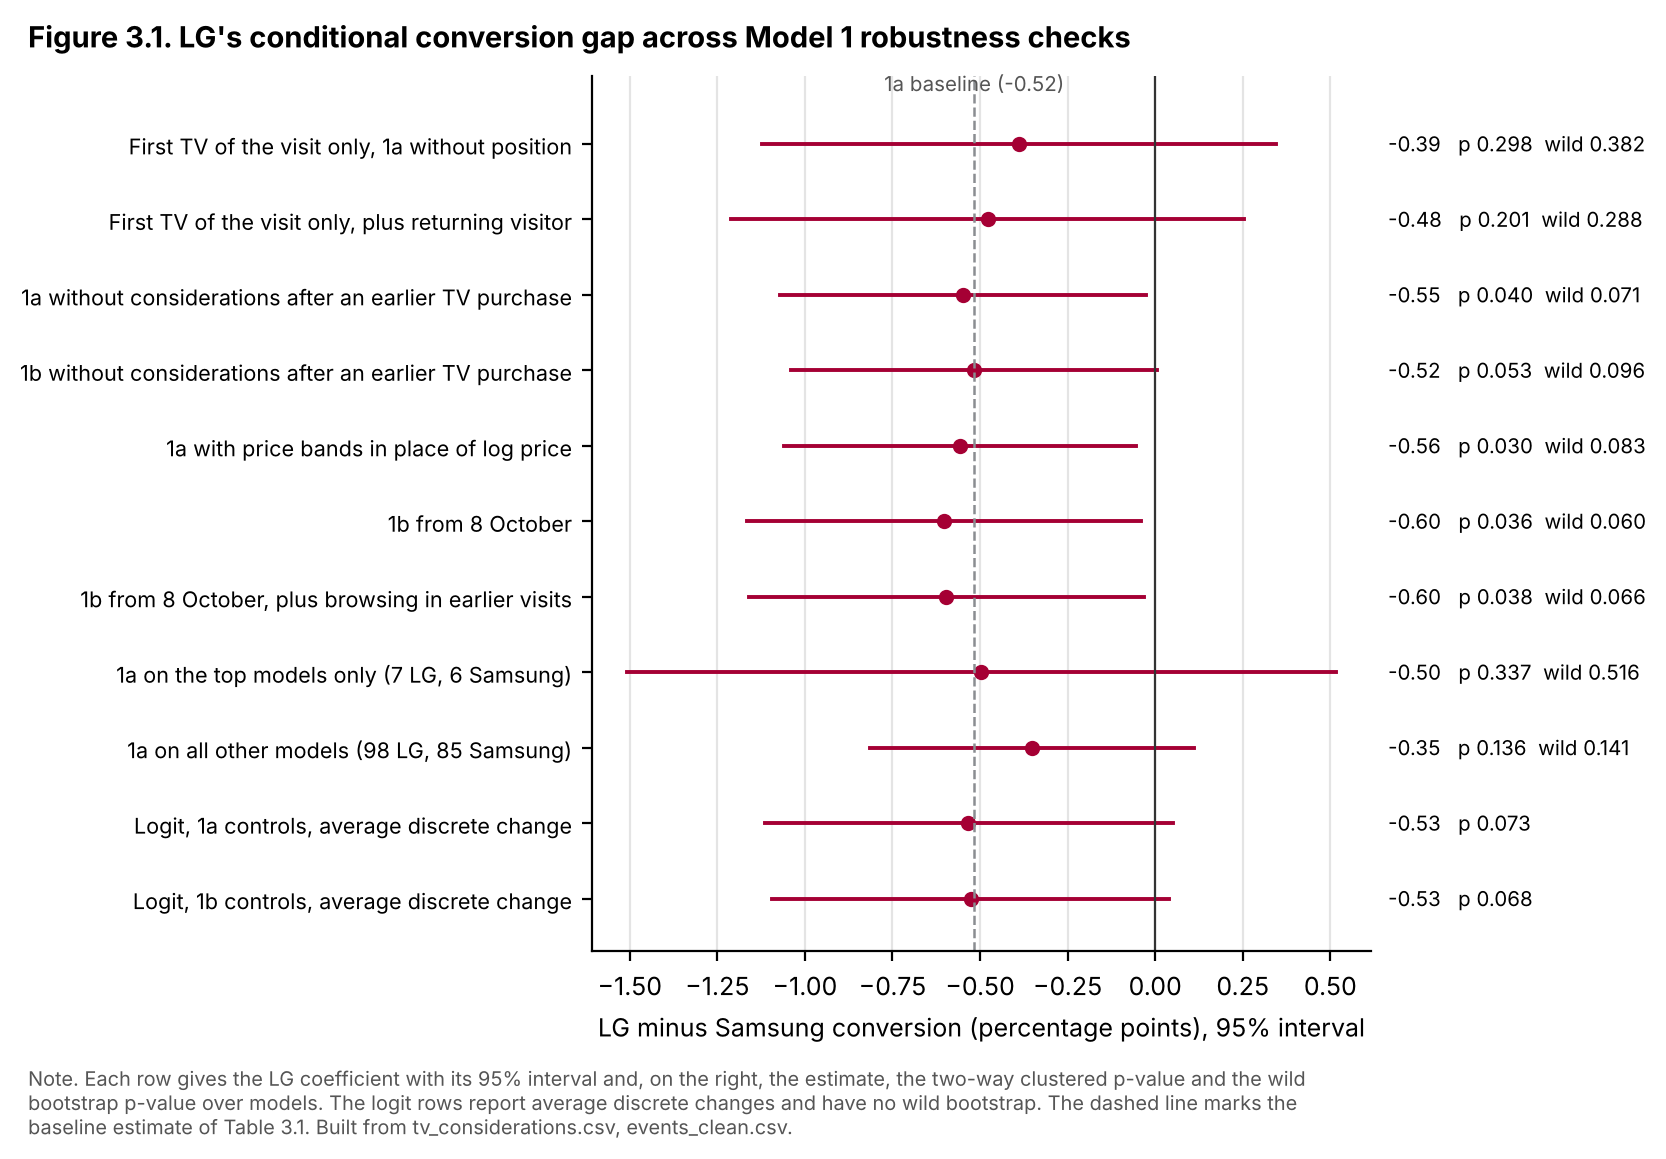

In [6]:
fig, (ax, axr) = plt.subplots(1, 2, figsize=(8.2, 5.2), sharey=True, layout='constrained',
                              gridspec_kw={'width_ratios': [3.2, 1]})
ypos = np.arange(len(rob))[::-1]
base = fits['1a'].params['lg']
for y0, (label, r) in zip(ypos, rob.iterrows()):
    b, lo_, hi_ = r['Coefficient (pp)'], r['95% CI low (pp)'], r['95% CI high (pp)']
    ax.plot([lo_, hi_], [y0, y0], color='#A50034', lw=1.4)
    ax.plot(b, y0, 'o', color='#A50034', ms=4.5)
    wild_txt = '' if np.isnan(r['p-value, wild bootstrap over models']) else f"  wild {r['p-value, wild bootstrap over models']:.3f}"
    axr.text(0, y0, f"{b:.2f}   p {r['p-value, two-way clustered']:.3f}{wild_txt}", va='center', fontsize=7.4)
ax.axvline(0, color='#333333', lw=0.8)
ax.axvline(base, color='#8A8D91', lw=0.9, ls='--')
ax.text(base, len(rob) - 0.3, f'1a baseline ({base:.2f})', ha='center', fontsize=7.4, color='#555555')
ax.set_yticks(ypos)
ax.set_yticklabels(rob.index, fontsize=7.8)
ax.set_ylim(-0.7, len(rob) - 0.1)
ax.set_xlabel('LG minus Samsung conversion (percentage points), 95% interval')
ax.grid(axis='y', visible=False)
axr.axis('off')
save_figure(fig, '3.1', "LG's conditional conversion gap across Model 1 robustness checks",
            'Each row gives the LG coefficient with its 95% interval and, on the right, the estimate, the two-way clustered '
            'p-value and the wild bootstrap p-value over models. The logit rows report average discrete changes and have no '
            'wild bootstrap. The dashed line marks the baseline estimate of Table 3.1.', [F_CONS, F_EV])

### What the checks show

Across the nine linear alternatives LG's coefficient lies between −0.35 and −0.60 points, and the logit gives −0.53 points with both sets of controls.

The two procedures differ in what they find significant. Four alternatives give two-way p-values between 0.030 and 0.040, namely 1a without the considerations after an earlier TV purchase, 1a with price bands, and 1b from 8 October with and without browsing in earlier visits. The first-TV checks give 0.30 and 0.20, and the split into top and other models gives 0.34 and 0.14. Under the wild bootstrap over models, which allows dependence only within a model, every p-value lies between 0.06 and 0.52.

The conditional gap of about half a point is therefore stable in size across specifications, while its statistical support is borderline. The baseline is not significant at the 5% level, and some alternatives are under the two-way procedure.

## 4. Model 2. Choice among the models opened before the purchase

Model 2 compares models that one shopper opened in one visit. In a visit that ended with one TV model bought, the models opened up to the moment of the purchase form the set the shopper chose from. The question is whether the LG model was less often the one bought, given its price, whether it was the first TV opened and whether it is a top model.

Each visit gets its own fixed effect. Everything that is the same throughout a visit drops out of the comparison, including the shopper's budget, urgency and taste, the device, whether they are a returning visitor, and the week. Visit fixed effects do not absorb brand-specific preferences of the shopper, or attributes of the models that the covariates leave out. A conditional logit estimates the model without estimating each visit's fixed effect separately.

**Choice sets.** The sample is built in four steps.
1. Start from visits with two or more TV considerations and exactly one purchased consideration. Visits with purchases of more than one model are left out, since a choice model needs one chosen option.
2. Find the time of the chosen model's first purchase event at or after its first view, from the TV events in `events_clean.csv`.
3. Drop any visit that also contains a purchase event for another TV model, including purchases that have no qualifying consideration.
4. Keep only the alternatives first viewed at or before the purchase time, then keep the visits that still have two or more alternatives.

An alternative first viewed in the same second as the purchase would count as opened before it. The code reports how many such alternatives there are.

**Assumptions.** The conditional logit assumes that the odds between two opened models do not depend on which other models were opened. The set of opened models results from the shopper's search and the site's displays, and nobody assigned it at random. The sample covers only visits with a purchase and at least two options, so the estimate describes choices within those visits. Conversion is the subject of Model 1.

**Covariates.** These are LG and the other four brands (each against Samsung), log price, whether the model was the first TV opened in the visit, and whether it is a top model. With visit fixed effects, log price compares the models within the same visit.

In [7]:
X2 = ['lg', 'other_four', 'log_price', 'first_tv', 'top_model']
vis = cons.groupby('visit').agg(n=('product_id', 'size'), buys=('purchased', 'sum'))
cand = cons[cons['visit'].isin(vis.index[(vis['n'] >= 2) & (vis['buys'] == 1)])].copy()
purchases = events.loc[(events['event_type'] == 'purchase') & events['visit'].isin(cand['visit']),
                       ['visit', 'product_id', 'event_time']]
chosen = cand.loc[cand['purchased'] == 1, ['visit', 'product_id', 'first_view']]
ptime = chosen.merge(purchases, on=['visit', 'product_id'])
ptime = ptime[ptime['event_time'] >= ptime['first_view']].groupby('visit')['event_time'].min().rename('purchase_time')
other_buy = purchases.merge(chosen[['visit', 'product_id']], on='visit', suffixes=('', '_chosen'))
other_buy = set(other_buy.loc[other_buy['product_id'] != other_buy['product_id_chosen'], 'visit'])
cand = cand.join(ptime, on='visit')
assert cand['purchase_time'].notna().all()
late_alt = cand['first_view'] > cand['purchase_time']
ch = cand[~late_alt & ~cand['visit'].isin(other_buy)]
ch = ch[ch.groupby('visit')['product_id'].transform('size') >= 2].sort_values(['visit', 'first_view']).reset_index(drop=True)
assert (ch.groupby('visit')['purchased'].sum() == 1).all() and (ch.groupby('visit')['first_tv'].sum() == 1).all()
by_visit = ch.groupby('visit').agg(has_lg=('lg', 'max'), has_samsung=('brand_group', lambda s: (s == 'samsung').any()))
hh = ch[ch['visit'].isin(by_visit.index[by_visit['has_lg'].astype(bool) & by_visit['has_samsung']])].reset_index(drop=True)
s1 = cand[~cand['visit'].isin(other_buy)]
s2 = s1[s1['first_view'] <= s1['purchase_time']]
assert len(s2[s2.groupby('visit')['product_id'].transform('size') >= 2]) == len(ch)
counts = lambda d: (f"{len(d):,}", f"{d['visit'].nunique():,}")
same_second = (ch['first_view'] == ch['purchase_time']) & (ch['purchased'] == 0)
flow = pd.DataFrame([
    ('Visits with two or more considerations and one purchased consideration', *counts(cand)),
    ('After dropping visits with a purchase event for another product', *counts(s1)),
    ('After dropping alternatives first viewed after the purchase', *counts(s2)),
    ('After dropping visits left with fewer than two alternatives (final sample)', *counts(ch)),
    ('Final sample, alternatives first viewed in the same second as the purchase (kept)', f"{int(same_second.sum()):,}", ''),
    ('Final sample, visits that include an LG model', '', f"{int(by_visit['has_lg'].sum()):,}"),
    ('Final sample, visits that ended in an LG purchase', '', f"{int(ch.loc[ch['lg'] == 1, 'purchased'].sum()):,}"),
    ('Final sample, visits that include both LG and Samsung', *counts(hh)),
], columns=['Step', 'Alternatives', 'Visits']).set_index('Step')
t33 = save_table('3.3', 'Model 2 choice sample', flow, [F_CONS, F_EV],
                 'The first four rows apply the sample rules in order, and each gives the alternatives and visits left after '
                 'its step. The last four rows describe the final sample.')

**Table 3.3. Model 2 choice sample**

,Alternatives,Visits
Step,,
Visits with two or more considerations and one purchased consideration,"4,302","1,265"
After dropping visits with a purchase event for another product,"4,297","1,264"
After dropping alternatives first viewed after the purchase,"4,149","1,264"
After dropping visits left with fewer than two alternatives (final sample),"4,105","1,220"
"Final sample, alternatives first viewed in the same second as the purchase (kept)",0,
"Final sample, visits that include an LG model",,382
"Final sample, visits that ended in an LG purchase",,188
"Final sample, visits that include both LG and Samsung","1,311",263


*Note.* The first four rows apply the sample rules in order, and each gives the alternatives and visits left after its step. The last four rows describe the final sample. Built from tv_considerations.csv, events_clean.csv.

The estimator below maximises the conditional logit likelihood by Newton's method and reports the largest absolute gradient at the solution, which should be close to zero. Its coefficients and model-based standard errors are compared with those of the conditional logit in statsmodels.

The clustered errors need a score for each row, so that rows can be grouped by user and by model. The score of a visit is the sum over its rows of (purchased − fitted probability) × covariate. Because the fitted probabilities in a visit sum to one, the same total is obtained when each row's covariate is measured as a deviation from the visit's probability-weighted average. The notebook uses these centred row scores. Unlike the raw row scores, they do not change when a constant is added to a covariate, which leaves the estimator unchanged, and that property is required for the grouping by model to be meaningful.

A bootstrap resamples users with replacement (999 draws) and re-estimates the model each time, weighting each user's visits by the number of times the user is drawn, which is equivalent to duplicating them. It checks the part of the clustered errors that comes from users. It does not check how the centred scores are allocated to models, or the two-way covariance that results. Resampling alternatives by model would change the choice sets, so it is not used.

In [8]:
def clogit_fit(X, y, g, w=None, tol=1e-10, max_iter=100):
    G, k = g.max() + 1, X.shape[1]
    w = np.ones(len(y)) if w is None else w
    wg = np.zeros(G); wg[g] = w

    def parts(b):
        v = X @ b
        vmax = np.full(G, -np.inf); np.maximum.at(vmax, g, v)
        e = np.exp(v - vmax[g])
        den = np.bincount(g, weights=e, minlength=G)
        p = e / den[g]
        ll = np.sum(w * y * (v - vmax[g] - np.log(den[g])))
        grad = ((w * (y - p))[:, None] * X).sum(0)
        spx = np.zeros((G, k)); np.add.at(spx, g, X * p[:, None])
        H = (X * (w * p)[:, None]).T @ X - (spx * wg[:, None]).T @ spx
        return ll, grad, H, p, spx

    b = np.zeros(k)
    for it in range(1, max_iter + 1):
        ll, grad, H, p, spx = parts(b)
        if np.abs(grad).max() < tol:
            break
        step, t = np.linalg.solve(H, grad), 1.0
        while parts(b + t * step)[0] < ll - 1e-12 and t > 1e-6:
            t /= 2
        b = b + t * step
    ll, grad, H, p, spx = parts(b)
    return b, H, p, spx, {'Newton iterations': it, 'Converged': bool(np.abs(grad).max() < tol),
                          'Largest absolute gradient': float(np.abs(grad).max()), 'Log-likelihood': float(ll)}


def clogit(d, cols):
    X, y = d[cols].to_numpy(float), d['purchased'].to_numpy(float)
    g = pd.factorize(d['visit'])[0]
    b, H, p, spx, info = clogit_fit(X, y, g)
    assert info['Converged'], 'Newton iterations reached the limit without convergence'
    Hinv = np.linalg.inv(H)
    s = (X - spx[g]) * (y - p)[:, None]

    def meat(codes):
        sc = np.zeros((codes.max() + 1, X.shape[1])); np.add.at(sc, codes, s)
        return len(sc) / (len(sc) - 1) * sc.T @ sc

    cu, cm = pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]
    cum = pd.factorize(d['user_id'] + '|' + d['product_id'])[0]
    V = Hinv @ (meat(cu) + meat(cm) - meat(cum)) @ Hinv
    se = np.sqrt(np.diag(V))
    ses = pd.DataFrame({'Two-way (user and model)': se, 'One-way by user': np.sqrt(np.diag(Hinv @ meat(cu) @ Hinv)),
                        'One-way by model': np.sqrt(np.diag(Hinv @ meat(cm) @ Hinv)),
                        'Model-based': np.sqrt(np.diag(Hinv))}, index=cols)
    est = pd.DataFrame({'Coefficient': b, 'Standard error': se, 'p-value, two-way clustered': 2 * stats.norm.sf(np.abs(b / se)),
                        'Odds ratio': np.exp(b), 'Odds ratio, 95% CI low': np.exp(b - 1.96 * se),
                        'Odds ratio, 95% CI high': np.exp(b + 1.96 * se)}, index=cols)
    return est, ses, V, info


m2_all, m2_ses, m2_V, m2_info = clogit(ch, X2)
m2_hh, _, _, _ = clogit(hh, X2)
from statsmodels.discrete.conditional_models import ConditionalLogit
ref = ConditionalLogit(ch['purchased'], ch[X2].astype(float), groups=pd.factorize(ch['visit'])[0]).fit(disp=False)
m2_ses['statsmodels model-based'] = ref.bse.to_numpy()
gap = np.abs(ref.params.to_numpy() - m2_all['Coefficient'].to_numpy()).max()
print(f"Largest coefficient difference from statsmodels {gap:.1e}; log-likelihood here {m2_info['Log-likelihood']:.4f}, "
      f"statsmodels {ref.llf:.4f}")
assert gap < 2e-3 and m2_info['Log-likelihood'] >= ref.llf - 1e-6

Xc, yc, gc = ch[X2].to_numpy(float), ch['purchased'].to_numpy(float), pd.factorize(ch['visit'])[0]
ucode, users = pd.factorize(ch['user_id'])
W = np.random.default_rng(SEED).multinomial(len(users), np.full(len(users), 1 / len(users)), size=999).astype(float)
res = [(f[0], f[4]['Converged']) for f in (clogit_fit(Xc, yc, gc, w=wu[ucode]) for wu in W)]
boot_ok = np.array([ok for _, ok in res])
boot = np.array([b for b, ok in res if ok])
print(f'Bootstrap draws that converged: {boot_ok.sum()} of {len(W)}')
m2_ses['Bootstrap over users'] = boot.std(0, ddof=1)

within = ch[['purchased_pp'] + X2] - ch.groupby('visit')[['purchased_pp'] + X2].transform('mean')
within[['user_id', 'product_id']] = ch[['user_id', 'product_id']]
m2_lpm = ols2('purchased_pp ~ ' + ' + '.join(X2) + ' - 1', within)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    m2_dummies = ols2('purchased_pp ~ ' + ' + '.join(X2) + ' + C(visit) - 1', ch)
    dummies_se, dummies_p = m2_dummies.bse['lg'], m2_dummies.pvalues['lg']
assert abs(m2_dummies.params['lg'] - m2_lpm.params['lg']) < 1e-8
print(f"Linear model with visit fixed effects, LG: {m2_lpm.params['lg']:.3f} pp, standard error "
      f"{m2_lpm.bse['lg']:.3f} with the visit effects left out of the small-sample correction and "
      f"{dummies_se:.3f} with explicit visit dummies, which counts all {ch['visit'].nunique():,} visit effects")

NAMES2 = {'lg': 'LG (against Samsung)', 'other_four': 'Other four brands (against Samsung)', 'log_price': 'Log price',
          'first_tv': 'First TV opened in the visit', 'top_model': 'Top model (retrospective split)'}
fmt = lambda e, v: f"{e.loc[v, 'Coefficient']:.3f} ({e.loc[v, 'Standard error']:.3f})"
ci = lambda e: f"{e.loc['lg', 'Odds ratio']:.2f} ({e.loc['lg', 'Odds ratio, 95% CI low']:.2f} to {e.loc['lg', 'Odds ratio, 95% CI high']:.2f})"
t34 = pd.DataFrame({
    'Conditional logit, all choice visits': [fmt(m2_all, v) for v in X2],
    'Conditional logit, visits with LG and Samsung': [fmt(m2_hh, v) for v in X2],
    'Linear model with visit fixed effects (pp)': [f"{m2_lpm.params[v]:.2f} ({m2_lpm.bse[v]:.2f})" for v in X2],
}, index=[NAMES2[v] for v in X2])
t34.loc['Odds ratio for LG, 95% CI'] = [ci(m2_all), ci(m2_hh), '']
t34.loc['p-value for LG, two-way clustered'] = [f"{m2_all.loc['lg', 'p-value, two-way clustered']:.3f}",
                                                f"{m2_hh.loc['lg', 'p-value, two-way clustered']:.3f}", f"{m2_lpm.pvalues['lg']:.3f}"]
t34.loc['p-value for LG, visit effects counted in the small-sample correction'] = ['', '', f"{dummies_p:.3f}"]
t34 = save_table('3.4', 'Model 2. Which of the models opened before the purchase was bought, with one fixed effect per visit',
                 t34, [F_CONS, F_EV], 'Coefficients with two-way clustered standard errors in brackets. The conditional '
                 'logit coefficients are in log odds and the linear model is in percentage points. The linear model leaves '
                 'the visit effects out of the small-sample correction of its standard errors, because each visit lies '
                 'within one user and users are one of the two cluster dimensions. The last row counts all '
                 f"{ch['visit'].nunique():,} visit effects by estimating them as explicit dummies. Table 3.3 gives the "
                 'visits and alternatives in each sample.')
t35 = m2_ses.round(3)
t35.index = [NAMES2[v] for v in X2]
t35 = save_table('3.5', 'Model 2 checks: standard errors of the conditional logit under different procedures', t35,
                 [F_CONS, F_EV], 'Standard errors of the coefficients in the first column of Table 3.4. The statsmodels '
                 'column checks the model-based errors of the estimator written here, and the bootstrap over users checks the '
                 'part of the clustered errors that comes from users. Neither check covers how the scores are allocated to '
                 'models in the two-way errors.')
print(m2_info)

Largest coefficient difference from statsmodels 4.1e-04; log-likelihood here -1113.6421, statsmodels -1113.6421


Bootstrap draws that converged: 999 of 999


Linear model with visit fixed effects, LG: -6.727 pp, standard error 3.006 with the visit effects left out of the small-sample correction and 3.586 with explicit visit dummies, which counts all 1,220 visit effects


**Table 3.4. Model 2. Which of the models opened before the purchase was bought, with one fixed effect per visit**

,"Conditional logit, all choice visits","Conditional logit, visits with LG and Samsung",Linear model with visit fixed effects (pp)
LG (against Samsung),-0.247 (0.144),-0.233 (0.165),-6.73 (3.01)
Other four brands (against Samsung),0.238 (0.231),0.224 (0.419),6.27 (5.37)
Log price,0.406 (0.174),0.325 (0.256),7.80 (3.85)
First TV opened in the visit,-1.486 (0.098),-1.147 (0.209),-39.45 (1.80)
Top model (retrospective split),0.114 (0.173),0.264 (0.240),4.63 (3.43)
"Odds ratio for LG, 95% CI",0.78 (0.59 to 1.04),0.79 (0.57 to 1.09),
"p-value for LG, two-way clustered",0.086,0.157,0.025
"p-value for LG, visit effects counted in the small-sample correction",,,0.061


*Note.* Coefficients with two-way clustered standard errors in brackets. The conditional logit coefficients are in log odds and the linear model is in percentage points. The linear model leaves the visit effects out of the small-sample correction of its standard errors, because each visit lies within one user and users are one of the two cluster dimensions. The last row counts all 1,220 visit effects by estimating them as explicit dummies. Table 3.3 gives the visits and alternatives in each sample. Built from tv_considerations.csv, events_clean.csv.

**Table 3.5. Model 2 checks: standard errors of the conditional logit under different procedures**

,Two-way (user and model),One-way by user,One-way by model,Model-based,statsmodels model-based,Bootstrap over users
LG (against Samsung),0.144,0.137,0.127,0.140,0.140,0.141
Other four brands (against Samsung),0.231,0.174,0.213,0.177,0.177,0.179
Log price,0.174,0.129,0.164,0.148,0.148,0.127
First TV opened in the visit,0.098,0.090,0.088,0.088,0.088,0.092
Top model (retrospective split),0.173,0.125,0.161,0.121,0.121,0.128


*Note.* Standard errors of the coefficients in the first column of Table 3.4. The statsmodels column checks the model-based errors of the estimator written here, and the bootstrap over users checks the part of the clustered errors that comes from users. Neither check covers how the scores are allocated to models in the two-way errors. Built from tv_considerations.csv, events_clean.csv.

{'Newton iterations': 6, 'Converged': True, 'Largest absolute gradient': 2.3092638912203256e-13, 'Log-likelihood': -1113.6420533979872}


To make the odds ratio concrete, the cell below works through two hypothetical visits. In each, the shopper opened exactly one LG and one Samsung model at the same price, neither of them a top model, and bought one of the two. In a two-option visit one model is necessarily opened first, so the two scenarios differ in which brand came first. Each scenario is compared with the probability the model implies when the brand coefficient is set to zero. The intervals come from 20,000 draws of the coefficients from their estimated distribution with the two-way covariance.

The results are probabilities of being the model chosen within such a visit. They are fitted values within the observed sample of purchase visits, they have not been validated on other data, and they do not predict the effect of any action.

In [9]:
assert np.all(np.linalg.eigvalsh(m2_V) > 0), 'The two-way covariance of Model 2 is not positive definite'
draws = np.random.default_rng(SEED).multivariate_normal(m2_all['Coefficient'].to_numpy(), m2_V, size=20000)
b_lg, b_first = draws[:, 0], draws[:, 3]
point_lg, point_first = m2_all.loc['lg', 'Coefficient'], m2_all.loc['first_tv', 'Coefficient']
logistic = lambda x: 1 / (1 + np.exp(-x))
scen = {
    'Samsung opened first, LG second': (logistic(point_lg - point_first), logistic(b_lg - b_first), logistic(-b_first)),
    'LG opened first, Samsung second': (logistic(point_lg + point_first), logistic(b_lg + b_first), logistic(b_first)),
}
rows = []
for k, (pt, sim, bench) in scen.items():
    rows.append({'Hypothetical visit': k, 'Probability the LG model is the one bought (%)': 100 * pt,
                 '95% interval low (%)': 100 * np.percentile(sim, 2.5), '95% interval high (%)': 100 * np.percentile(sim, 97.5),
                 'Same probability with the brand coefficient set to zero (%)': 100 * np.median(bench)})
t36 = save_table('3.6', 'Model 2 in two hypothetical visits with one LG and one Samsung model', pd.DataFrame(rows).set_index('Hypothetical visit').round(1),
                 [F_CONS, F_EV], 'Both models have the same price and neither is a top model.')

**Table 3.6. Model 2 in two hypothetical visits with one LG and one Samsung model**

,Probability the LG model is the one bought (%),95% interval low (%),95% interval high (%),Same probability with the brand coefficient set to zero (%)
Hypothetical visit,,,,
"Samsung opened first, LG second",77.500,70.500,83.300,81.500
"LG opened first, Samsung second",15.000,11.500,19.300,18.500


*Note.* Both models have the same price and neither is a top model. Built from tv_considerations.csv, events_clean.csv.

### What Model 2 shows

Among the models opened before the purchase, an LG model is somewhat less often the one bought than a Samsung model with the same covariates. The odds ratio for LG is 0.78, with a 95% interval from 0.59 to 1.04 and a two-way clustered p-value of 0.086. In a hypothetical two-option visit where Samsung was opened first, the LG model is bought in 77.5% of such visits (interval 70.5% to 83.3%), against 81.5% if brand made no difference. Where LG was opened first, the LG model is bought in 15.0% (11.5% to 19.3%), against 18.5%.

The visits that include both an LG and a Samsung model give a similar odds ratio (0.79, p = 0.16). The linear model with visit fixed effects gives an LG model a 6.7-point lower chance of being the model bought. Its p-value is 0.025 when the visit effects are left out of the small-sample correction, because each visit lies within one user, and 0.061 when all 1,220 visit effects are counted (Table 3.4). The coefficient is the same under both conventions, so the convention changes only the strength of the statistical support, which is borderline in both specifications.

Newton's method converges in six iterations with a largest absolute gradient below 1e-12, and all 999 bootstrap draws converge. The coefficients agree with statsmodels to within 0.0004 at the same log-likelihood, and the model-based errors match to three decimals. The bootstrap over users (0.141 for LG) agrees with the sandwich clustered by user (0.137). The two-way error for LG (0.144) is the largest of the procedures (Table 3.5).

The first TV opened in a visit is much less likely to be the one bought (odds ratio 0.23), which fits the pattern that shoppers who go on browsing tend to buy something they find later. Within a visit, the more expensive of the models weighed is somewhat more likely to be bought. Price here probably tracks screen size and features, so this coefficient does not measure a response to price.

## 5. Model 3. Considerations per observed product

Model 3 moves from considerations to TV models. Each of the 196 LG and Samsung models observed with at least one view is one observation, and the outcome is the number of considerations it drew over the two months. Models that were listed but never viewed in the sample are not observed, so the population is the set of viewed models.

**What it measures.** A brand's considerations are the sum of its products' considerations. A product's count equals the number of visits that opened that product, but summing over a brand's products counts a visit once for every model of the brand it opened. The per-product count therefore combines reach, the breadth of browsing within a visit and the assortment, which matters because LG has more observed models than Samsung. Model 3 is an adjusted comparison of considerations per observed product. It is related to the reach factor in Figure 2.4 of `02_preliminary_analysis.ipynb` and does not re-estimate or test that share.

**Estimator.** A Poisson regression of the count on the LG indicator and log median price. Its LG coefficient b translates into a percentage difference, exp(b) − 1, in the expected count of an LG model compared with a Samsung model at the same median price, under the assumption that the expected count is an exponential function of the covariates. Robust errors (HC1) remain valid when the counts are more dispersed than a Poisson distribution, provided that the exponential mean is right. They do not correct a wrong mean, omitted product characteristics, or dependence between products that share shoppers. A bootstrap that resamples shoppers keeps each sampled shopper's contributions to all products together. It holds the set of observed products and their median prices fixed, so it measures sensitivity to the sampling of shoppers and does not replace the HC1 errors.

**Sensitivity.** The variants cover price bands, common price support, considerations per day of each model's observed activity span (from its first to its last recorded event, which can differ from the period in which the model was listed), removal of the top models of both brands, removal of Samsung's largest models, a check that drops one model at a time, and a linear regression of log considerations. The linear version models the mean of log counts, while the Poisson regression models the mean of counts, so the difference between the two estimates shows how sensitive the comparison is to the scale and the mean specification.

In [10]:
span = events.groupby('product_id')['event_time'].agg(['min', 'max'])
mod = (ls.groupby('product_id')
         .agg(considerations=('purchased', 'size'), median_price=('price', 'median'), lg=('lg', 'max'),
              top_model=('top_model', 'max'))
         .join(span))
mod['log_median_price'] = np.log(mod['median_price'])
mod['activity_span_days'] = (mod['max'].dt.normalize() - mod['min'].dt.normalize()).dt.days + 1
mod['log_considerations'] = np.log(mod['considerations'])
mod['price_band'] = pd.cut(mod['median_price'], [0, 300, 450, 650, 1000, np.inf],
                           labels=['Under 300', '300 to 450', '450 to 650', '650 to 1,000', 'Over 1,000'])
lo_p, hi_p = mod.groupby('lg')['median_price'].min().max(), mod.groupby('lg')['median_price'].max().min()
common = mod[mod['median_price'].between(lo_p, hi_p)]
samsung_largest = mod[mod['lg'] == 0]['considerations'].nlargest(5).index
print(mod.groupby('lg')[['considerations', 'median_price']].median().rename(index={0: 'Samsung median', 1: 'LG median'}))

F3 = 'considerations ~ lg + log_median_price'
poisson = lambda f, d, offset=None: smf.glm(f, d, family=sm.families.Poisson(), offset=offset).fit(cov_type='HC1')
FITS3 = [
    ('Poisson, log median price (main)', poisson(F3, mod)),
    ('Poisson, price bands', poisson('considerations ~ lg + C(price_band)', mod)),
    (f'Poisson, common price support ({lo_p:.0f} to {hi_p:.0f})', poisson(F3, common)),
    ('Poisson, per day of observed activity span', poisson(F3, mod, offset=np.log(mod['activity_span_days']))),
    ('Poisson, without the 13 top models of both brands', poisson(F3, mod[mod['top_model'] == 0])),
    ('Poisson, without Samsung\'s largest model', poisson(F3, mod.drop(samsung_largest[:1]))),
    ('Poisson, without Samsung\'s three largest models', poisson(F3, mod.drop(samsung_largest[:3]))),
    ('Poisson, without Samsung\'s five largest models', poisson(F3, mod.drop(samsung_largest[:5]))),
    ('Linear, log considerations', smf.ols('log_considerations ~ lg + log_median_price', mod).fit(cov_type='HC1')),
]
t37 = pd.DataFrame([{'LG coefficient': r.params['lg'], 'Standard error': r.bse['lg'],
                     'LG against Samsung (%)': 100 * (np.exp(r.params['lg']) - 1),
                     '95% CI low (%)': 100 * (np.exp(r.params['lg'] - 1.96 * r.bse['lg']) - 1),
                     '95% CI high (%)': 100 * (np.exp(r.params['lg'] + 1.96 * r.bse['lg']) - 1),
                     'p-value': r.pvalues['lg'], 'Models': int(r.nobs)} for _, r in FITS3],
                   index=[k for k, _ in FITS3]).round(3)
t37.index.name = 'Specification'

loo = pd.Series({p: smf.glm(F3, mod.drop(p), family=sm.families.Poisson()).fit().params['lg'] for p in mod.index})
uc = pd.factorize(ls['user_id'])[0]
pc = pd.Categorical(ls['product_id'], categories=mod.index).codes
counts_by_user = sparse.csr_matrix((np.ones(len(ls)), (uc, pc)), shape=(uc.max() + 1, len(mod)))
Xm = sm.add_constant(mod[['lg', 'log_median_price']].to_numpy(float))
start = FITS3[0][1].params.to_numpy()
Wp = np.random.default_rng(SEED).poisson(1.0, size=(999, uc.max() + 1)).astype(float)
boot3 = np.array([sm.GLM(np.asarray(counts_by_user.T @ w).ravel(), Xm, family=sm.families.Poisson()).fit(
    start_params=start).params[1] for w in Wp])
t37 = save_table('3.7', 'Model 3. Considerations per observed LG model against a Samsung model at the same price', t37,
                 [F_CONS, F_EV], 'Poisson rows use HC1 standard errors. The percentage difference is exp(b) − 1.')
print(f"Dropping one model at a time, the main LG coefficient ranges from {loo.min():.3f} to {loo.max():.3f} "
      f"(main {FITS3[0][1].params['lg']:.3f}). The three most influential models:")
influential = loo.sub(FITS3[0][1].params['lg']).abs().nlargest(3).index
display(pd.DataFrame({'Brand': mod.loc[influential, 'lg'].map({1: 'LG', 0: 'Samsung'}),
                      'Considerations': mod.loc[influential, 'considerations'],
                      'Rank within its brand': [int((mod.loc[mod['lg'] == mod.loc[p, 'lg'], 'considerations'] > mod.loc[p, 'considerations']).sum()) + 1
                                                for p in influential],
                      'LG coefficient without it': loo[influential].round(3)}))
print(f"Bootstrap over shoppers (999 Poisson-weighted draws): standard error {boot3.std(ddof=1):.3f}, "
      f"95% interval {np.percentile(boot3, 2.5):.3f} to {np.percentile(boot3, 97.5):.3f}; HC1 standard error {FITS3[0][1].bse['lg']:.3f}")

                considerations  median_price
lg                                          
Samsung median          86.000       849.190
LG median               65.000       771.680


**Table 3.7. Model 3. Considerations per observed LG model against a Samsung model at the same price**

,LG coefficient,Standard error,LG against Samsung (%),95% CI low (%),95% CI high (%),p-value,Models
Specification,,,,,,,
"Poisson, log median price (main)",-0.890,0.299,-58.952,-77.174,-26.183,0.003,196
"Poisson, price bands",-0.951,0.306,-61.356,-78.800,-29.561,0.002,196
"Poisson, common price support (231 to 2574)",-0.934,0.297,-60.692,-78.036,-29.654,0.002,194
"Poisson, per day of observed activity span",-0.993,0.282,-62.965,-78.694,-35.624,0.000,196
"Poisson, without the 13 top models of both brands",-0.819,0.204,-55.916,-70.448,-34.236,0.000,183
"Poisson, without Samsung's largest model",-0.737,0.291,-52.128,-72.961,-15.244,0.011,195
"Poisson, without Samsung's three largest models",-0.495,0.279,-39.048,-64.752,5.398,0.076,193
"Poisson, without Samsung's five largest models",-0.281,0.270,-24.487,-55.525,28.211,0.298,191
"Linear, log considerations",-0.290,0.286,-25.139,-57.247,31.083,0.311,196


*Note.* Poisson rows use HC1 standard errors. The percentage difference is exp(b) − 1. Built from tv_considerations.csv, events_clean.csv.

Dropping one model at a time, the main LG coefficient ranges from -1.003 to -0.737 (main -0.890). The three most influential models:


,Brand,Considerations,Rank within its brand,LG coefficient without it
P000507,Samsung,9106,1,-0.737
P000554,Samsung,6865,2,-0.766
P000640,LG,2723,1,-1.003


Bootstrap over shoppers (999 Poisson-weighted draws): standard error 0.012, 95% interval -0.914 to -0.867; HC1 standard error 0.299


### What Model 3 shows

At the same median price, an observed LG model draws about 59% fewer considerations than an observed Samsung model, with a 95% interval from 26% to 77% fewer. The estimate is similar with price bands (61% fewer), on common price support (61% fewer), per day of observed activity span (63% fewer) and without the top models of both brands (56% fewer). Resampling shoppers gives a standard error of 0.012, against 0.299 from HC1 across products. The two procedures vary different parts of the data, so the comparison shows neither that dependence through shared shoppers is negligible nor which source dominates the total uncertainty.

The estimate is sensitive to Samsung's largest models. Dropping any single model leaves the coefficient between −1.00 and −0.74, and the three most influential models are Samsung's two largest and LG's largest. Dropping Samsung's three largest models while keeping LG's gives 39% fewer considerations (p = 0.08), and dropping its five largest gives 24% fewer, with an interval that includes zero. The linear model of log counts gives 25% fewer (interval −57% to +31%). The Poisson estimate gives more weight to models with many considerations, so the difference between the two estimates and the removal checks both show that much of the per-product gap comes from a few Samsung models with very large traffic, in line with Table 2.12 of `02_preliminary_analysis.ipynb`.

## 6. Model 4. Price changes within a model (optional extension)

Most LG and Samsung TV models changed their recorded price during the two months (Table 3.8). Model 4 describes how traffic and conversion move when the same model's recorded price changes. A model fixed effect gives each TV model its own baseline, which absorbs everything fixed about it, such as brand, screen size, page and usual placement. The price coefficient then comes from changes in each model's own price over time. A week or day fixed effect absorbs shifts common to all models in that period.

- **4a, conversion.** A linear probability model of purchase on log price, with model and week fixed effects and position in the visit, on the 74,712 LG and Samsung considerations, using the price at each first view. An LG × log price term asks whether the association differs for LG. LG's main effect is absorbed by the model fixed effects.
- **4b, traffic.** A Poisson regression of the number of considerations a model draws each day on its log price, with model and day fixed effects, clustered by model. The panel covers each model from the first to the last day of its observed activity span. The daily price is the median recorded price over the model's events that day. On days without events no price is recorded, and the last recorded price is carried forward (or the first one carried back).
- **4c, traffic by week.** The same with weeks in place of days.

The measurement limits are set out by the cell below. It counts the model-days whose price is carried over and compares the main estimate with an estimate that uses only days with a recorded price. It also checks two alternative rules, prices recorded on view events only and an activity span built from views only.

In [11]:
pv = events[events['brand'].isin(['lg', 'samsung'])].groupby(['brand', 'product_id'])['price'].agg(['min', 'max', 'nunique'])
t38 = pd.DataFrame({
    {'lg': 'LG', 'samsung': 'Samsung'}[br]: {
        'Models whose recorded price changed (%)': 100 * (d['nunique'] > 1).mean(),
        'Highest over lowest price minus one, median among those models (%)':
            100 * (d.loc[d['nunique'] > 1, 'max'] / d.loc[d['nunique'] > 1, 'min'] - 1).median()}
    for br, d in pv.groupby(level='brand')}).round(1)
t38.index.name = 'Measure'
t38 = save_table('3.8', 'Price changes within LG and Samsung models', t38, [F_EV],
                 'Prices recorded on all TV events of each model over the two months.')

TEN = np.log(1.1)
r4a = ols2('purchased_pp ~ log_price + log_price:lg + C(product_id) + C(week) + C(position)', ls)
r4a0 = ols2('purchased_pp ~ log_price + C(product_id) + C(week) + C(position)', ls)
ev = events[events['product_id'].isin(mod.index)].assign(day=lambda d: d['event_time'].dt.normalize())


def price_panel(freq='D', price_from='all', span_from='all'):
    to_period = (lambda s: s) if freq == 'D' else (lambda s: s - pd.to_timedelta(s.dt.weekday, unit='D'))
    src = ev if price_from == 'all' else ev[ev['event_type'] == 'view']
    rec = src.assign(period=to_period(src['day'])).groupby(['product_id', 'period'])['price'].median()
    win = (ev if span_from == 'all' else ev[ev['event_type'] == 'view']).groupby('product_id')['day'].agg(['min', 'max'])
    out = []
    for pid, (lo, hi) in win.iterrows():
        lo, hi = to_period(pd.Series([lo, hi])).tolist()
        periods = pd.date_range(lo, hi, freq='D' if freq == 'D' else '7D')
        r = rec.loc[pid].reindex(periods)
        out.append(pd.DataFrame({'product_id': pid, 'period': periods, 'price': r.ffill().bfill().to_numpy(),
                                 'price_recorded': r.notna().to_numpy()}))
    out = pd.concat(out, ignore_index=True)
    n = ls.assign(period=to_period(ls['first_view'].dt.normalize())).groupby(['product_id', 'period']).size()
    out = out.merge(n.rename('considerations'), on=['product_id', 'period'], how='left').fillna({'considerations': 0})
    assert out['considerations'].sum() == len(ls)
    out['log_price'] = np.log(out['price'])
    out['lg'] = out['product_id'].map(mod['lg'])
    out['period_s'] = out['period'].dt.strftime('%m-%d')
    return out


def ppml_fe(d, inter=False):
    f = 'considerations ~ log_price' + (' + log_price:lg' if inter else '') + ' + C(product_id) + C(period_s)'
    return smf.glm(f, d, family=sm.families.Poisson()).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d['product_id'])[0]})


daily, weekly = price_panel('D'), price_panel('W')
print(pd.crosstab(daily['price_recorded'], daily['considerations'] > 0, rownames=['Price recorded that day'],
                  colnames=['At least one consideration that day']))
print(f"Daily panel: {len(daily):,} model-days, price carried over on {(~daily['price_recorded']).mean():.1%}; "
      f"weekly panel: {len(weekly):,} model-weeks, price carried over on {(~weekly['price_recorded']).mean():.1%}")
dev = ls['log_price'] - ls.groupby('product_id')['log_price'].transform('mean')
print(f"Within-model standard deviation of log price at the first view: {dev.std():.3f}")


def effect(r, term, kind):
    b, se = r.params[term], r.bse[term]
    if kind == 'pp':
        e, lo, hi, unit = b * TEN, (b - 1.96 * se) * TEN, (b + 1.96 * se) * TEN, 'pp'
    else:
        e, lo, hi = [100 * (np.exp(x * TEN) - 1) for x in (b, b - 1.96 * se, b + 1.96 * se)]
        unit = '%'
    return {'Coefficient on log price': b, 'Standard error': se, 'Associated change for a 10% higher price': e,
            '95% CI low': lo, '95% CI high': hi, 'Unit': unit, 'p-value': r.pvalues[term], 'Observations': int(r.nobs)}


t39 = pd.DataFrame({
    '4a. Conversion, both brands': effect(r4a0, 'log_price', 'pp'),
    '4a. Conversion, LG minus Samsung': effect(r4a, 'log_price:lg', 'pp'),
    '4b. Daily considerations, both brands': effect(ppml_fe(daily), 'log_price', '%'),
    '4b. Daily considerations, LG relative to Samsung': effect(ppml_fe(daily, True), 'log_price:lg', '%'),
    '4b. Daily, only days with a recorded price': effect(ppml_fe(daily[daily['price_recorded']]), 'log_price', '%'),
    '4b. Daily, prices recorded on views only': effect(ppml_fe(price_panel('D', price_from='view')), 'log_price', '%'),
    '4b. Daily, activity span from views only': effect(ppml_fe(price_panel('D', span_from='view')), 'log_price', '%'),
    '4c. Weekly considerations, both brands': effect(ppml_fe(weekly), 'log_price', '%'),
    '4c. Weekly considerations, LG relative to Samsung': effect(ppml_fe(weekly, True), 'log_price:lg', '%'),
}).T
num = [c for c in t39.columns if c != 'Unit']
t39[num] = t39[num].astype(float).round(3)
t39.index.name = 'Model'
t39 = save_table('3.9', 'Model 4. Conversion and traffic when the same model\'s recorded price changes (optional extension)',
                 t39, [F_CONS, F_EV], 'Conversion rows are in percentage points and traffic rows in percent, for a 10% higher '
                 'price.')

**Table 3.8. Price changes within LG and Samsung models**

,LG,Samsung
Measure,,
Models whose recorded price changed (%),80.000,68.100
"Highest over lowest price minus one, median among those models (%)",14.800,13.400


*Note.* Prices recorded on all TV events of each model over the two months. Built from events_clean.csv.

At least one consideration that day  False  True 
Price recorded that day                          
False                                 3029      0
True                                     2   6374
Daily panel: 9,405 model-days, price carried over on 32.2%; weekly panel: 1,461 model-weeks, price carried over on 6.3%
Within-model standard deviation of log price at the first view: 0.038


**Table 3.9. Model 4. Conversion and traffic when the same model's recorded price changes (optional extension)**

,Coefficient on log price,Standard error,Associated change for a 10% higher price,95% CI low,95% CI high,Unit,p-value,Observations
Model,,,,,,,,
"4a. Conversion, both brands",3.883,2.930,0.370,-0.177,0.917,pp,0.185,"74,712.000"
"4a. Conversion, LG minus Samsung",1.407,5.762,0.134,-0.942,1.211,pp,0.807,"74,712.000"
"4b. Daily considerations, both brands",-2.678,0.411,-22.524,-28.244,-16.347,%,0.000,"9,405.000"
"4b. Daily considerations, LG relative to Samsung",-0.918,0.829,-8.377,-21.522,6.968,%,0.268,"9,405.000"
"4b. Daily, only days with a recorded price",-2.327,0.381,-19.891,-25.389,-13.988,%,0.000,"6,376.000"
"4b. Daily, prices recorded on views only",-2.675,0.409,-22.503,-28.210,-16.343,%,0.000,"9,405.000"
"4b. Daily, activity span from views only",-2.678,0.411,-22.524,-28.244,-16.347,%,0.000,"9,405.000"
"4c. Weekly considerations, both brands",-2.684,0.614,-22.571,-30.967,-13.153,%,0.000,"1,461.000"
"4c. Weekly considerations, LG relative to Samsung",-1.874,1.272,-16.354,-34.047,6.085,%,0.141,"1,461.000"


*Note.* Conversion rows are in percentage points and traffic rows in percent, for a 10% higher price. Built from tv_considerations.csv, events_clean.csv.

### What Model 4 shows

In the daily panel the price is carried over on 32.2% of model-days, and all of those days have no consideration. Only two days have a recorded price and no consideration. The days without traffic therefore largely coincide with the days whose price was carried over, and the main estimate depends on that imputation rule. This overlap alone does not show which observations determine the sign or the size of the price coefficient. Using only days with a recorded price gives 20% fewer considerations for a 10% higher price, against 23% in the main daily estimate. Prices recorded on view events only, and an activity span built from views only, give practically the same estimate as the main rule (22.5% fewer), so the choice of event type for prices and spans does not matter here. The weekly panel carries the price over on 6.3% of model-weeks and gives 23% fewer considerations.

Conversion shows no detectable association with the same model's price (+0.37 points for a 10% higher price, interval −0.18 to 0.92). LG's associations do not differ clearly from Samsung's on either measure.

These results describe associations under the stated price rule. The retailer may feature a model when its price changes, which the data do not show, and the price changes are small (a within-model standard deviation of about 4%). The model does not estimate a causal elasticity, a traffic lift or the effect of a discount, and the absence of a conversion association does not show that price works only through traffic.

## 7. Record of specification decisions

| Decision | When it was made | Reason |
| --- | --- | --- |
| Outcome, unit of analysis and two-way clustering by user and model | Before this notebook, in the descriptive analysis | Conventions of `02_preliminary_analysis.ipynb` |
| The four models and the controls of each version | After the descriptive analysis and before any model in this notebook was estimated | Controls known at the first view, chosen for timing and purpose |
| The first-TV check | Before estimation, after a question about position in the visit | Tests whether the gap survives at a single search stage |
| Symmetric history variables | Before estimation | The brand flags mean different things for LG and Samsung rows (see the dictionary) |
| Centred row scores in Model 2's clustered errors | After the first estimates, which gave implausibly large errors with raw row scores | Raw row scores change when a constant is added to a covariate |
| Per-day offset in Model 3 in place of days as a covariate | After the first estimates | The span is partly an outcome of traffic, so it enters only as a sensitivity |
| Choice sets closed at the purchase time, visits with another purchase dropped | After checking the first estimates | Alternatives opened after the purchase cannot be part of the choice. The odds ratio for LG was 0.78 before and after the change |
| Model 1 diagnostics, influence and shopper-bootstrap checks for Model 3, price-rule checks for Model 4 | After checking the first estimates | They test the assumptions each model relies on |
| A decomposition of the change in LG's coefficient by groups of controls was dropped | When the project files were consolidated | To keep the analysis on the main specifications and on the descriptive composition split in Table 2.7 of `02_preliminary_analysis.ipynb`. That table reweights conversion rates across groups and does not allocate a change in a coefficient |

In [12]:
pd.DataFrame(EXHIBITS).to_csv(OUT / 'exhibit_index.csv', index=False)
print(f"Saved {len(EXHIBITS)} exhibits to {OUT}")

Saved 10 exhibits to results/models


## 8. All exhibits in one file

The cell below collects the tables and figures saved by `00_scope_and_methodology_rationale.ipynb`, `02_preliminary_analysis.ipynb` and this notebook into `results/figures_and_tables.html`, in the order of the three notebooks.

In [13]:
import base64
import html
import re

RESULTS = Path('results')
PARTS = [('scope', '00. Research question and scope'), ('preliminary', '02. LG and Samsung TVs: descriptive analysis'),
         ('models', '03. Models')]


NUMBER = re.compile(r'^(-?)(\d+)(?:\.(\d+))?$')
P_LABEL = re.compile(r'\bp\b|p-value')


def fmt_cell(v, width, p_value, pad_whole):
    m = NUMBER.match(v)
    if not m:
        return v
    if p_value:
        return '<0.001' if float(v) < 0.0005 else f'{float(v):.3f}'
    sign, whole, frac = m.groups()
    if not frac or set(frac) == {'0'}:
        if pad_whole and abs(float(v)) < 100:
            return f'{sign}{int(whole):,}.' + '0' * width
        return f'{sign}{int(whole):,}'
    return f'{sign}{int(whole):,}.{frac.ljust(width, "0")}'


def fmt_table(df):
    out = df.copy()
    p_rows = df.iloc[:, 0].str.contains(P_LABEL)
    for j in range(1, df.shape[1]):
        col = df.iloc[:, j]
        fracs = [m.group(3) for v in col if (m := NUMBER.match(v)) and m.group(3)]
        width = max((len(f) for f in fracs if set(f) != {'0'}), default=0)
        whole = [v for v in col if (m := NUMBER.match(v)) and (not m.group(3) or set(m.group(3)) == {'0'})]
        pad_whole = width > 0 and len(whole) == 1
        p_col = bool(P_LABEL.search(str(df.columns[j])))
        out.iloc[:, j] = [fmt_cell(v, width, p_col or p_row, pad_whole) for v, p_row in zip(col, p_rows)]
    return out


css = ('body{font-family:Inter,Arial,sans-serif;font-size:12.5px;color:#1d1d1f;max-width:1120px;margin:24px auto;padding:0 16px}'
       'h1{font-size:19px;margin:30px 0 8px}h2{font-size:14px;margin:22px 0 6px;break-after:avoid}'
       'p.note{color:#555;font-size:11.5px;margin:4px 0 6px}table{border-collapse:collapse;font-size:11px;margin:6px 0 4px}'
       'th,td{border:1px solid #d0d3d8;padding:3px 6px;text-align:right;vertical-align:top}th{background:#f0f2f5}'
       'td:first-child,th:first-child{text-align:left}img{max-width:100%;max-height:175mm}'
       'table.index td{text-align:left}section{break-inside:avoid;page-break-inside:avoid;margin-bottom:20px}'
       '@page{size:A4 landscape;margin:11mm}')
indexes, body = [], []
for folder, heading in PARTS:
    idx_path = RESULTS / folder / 'exhibit_index.csv'
    if not idx_path.exists():
        print(f'{idx_path} not found; run the notebook that writes it first')
        continue
    idx = pd.read_csv(idx_path).fillna('')
    indexes.append(idx.assign(Notebook=heading))
    body.append(f'<h1>{html.escape(heading)}</h1>')
    for _, e in idx.iterrows():
        path = RESULTS / folder / e['File']
        body.append('<section>')
        if e['File'].startswith('tables'):
            df = pd.read_csv(path, dtype=str, keep_default_na=False)
            df.columns = ['' if str(c).startswith('Unnamed') else c for c in df.columns]
            body.append(f"<h2>{e['Exhibit']}. {html.escape(e['Title'])}</h2>")
            body.append(fmt_table(df).to_html(index=False))
            body.append(f"<p class='note'>Note. {html.escape(e['Note'])} Built from {html.escape(e['Built from'])}.</p>")
        else:
            body.append(f"<img src='data:image/png;base64,{base64.b64encode(path.read_bytes()).decode()}' "
                        f"alt='{html.escape(e['Exhibit'])}'>")
        body.append('</section>')
toc = pd.concat(indexes)[['Notebook', 'Exhibit', 'Title', 'Built from']]
page = (f'<!doctype html><html><head><meta charset="utf-8"><title>LG TV project: figures and tables</title><style>{css}</style>'
        '</head><body><h1>LG TV project: figures and tables</h1>'
        '<p class="note">Every table and figure produced by the three notebooks, in their order.</p>'
        f'{toc.to_html(index=False, classes="index")}' + '\n'.join(body) + '</body></html>')
(RESULTS / 'figures_and_tables.html').write_text(page, encoding='utf-8')
print(f"Wrote {RESULTS / 'figures_and_tables.html'} with {len(toc)} exhibits")

Wrote results/figures_and_tables.html with 38 exhibits
